In [1]:
# ===== imports =====
import torch, torchaudio
import torch.nn as nn
import torch.optim as optim
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import random
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# ===== device =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ===== settings =====
SAMPLE_RATE = 44100
HOP_SECONDS = 0.01
HOP   = int(HOP_SECONDS * SAMPLE_RATE)
N_FFT = 2048
N_MELS = 128
LABELS = ["Rest", "Sound", "Onset", "Offset"]
label_to_id = {n: i for i, n in enumerate(LABELS)}

# ===== paths (extended-4) =====
ROOT = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset")
ANNOT_CSV_DIR = ROOT / "annot_ext4_upload" / "annot_ext4_upload" / "annot"
AUDIO_DIR     = ROOT / "kaggle_upload" / "kaggle_upload" / "audio"

# ===== reader (no time-scaling) + labels =====
COLS = ["Sequence","Start","End","Duration","Type","AvgF0","MedF0","MinF0","MaxF0",
        "StdF0","AvgF0_inSTD","EstMIDI","GTNote","GTFreq","GTMIDI","Lyric",
        "GTDurName","GTDur","IntPrev","IntNext","Extra"]

def read_annot(csv_path):
    a = pd.read_csv(csv_path, skiprows=17, header=None, names=COLS)
    return a[["Start","End","Type"]].dropna(subset=["Start","End","Type"])

def frame_labels(annot, n_frames):
    labs = np.full(n_frames, label_to_id["Rest"], dtype=np.int64)
    for _, r in annot.iterrows():
        if r["Type"] == "Sound":
            lo, hi = int(r["Start"]/HOP_SECONDS), int(r["End"]/HOP_SECONDS)
            labs[lo:hi] = label_to_id["Sound"]
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        off = int(r["End"]/HOP_SECONDS)
        if off < n_frames: labs[off] = label_to_id["Offset"]
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        on = int(r["Start"]/HOP_SECONDS)
        if on < n_frames: labs[on] = label_to_id["Onset"]
    return labs

# ===== build clean file list (drop misaligned ~147) =====
csv_lookup = {p.stem: p for p in ANNOT_CSV_DIR.rglob("*.csv")}
pairs, dropped = [], 0
for wav in AUDIO_DIR.rglob("*.wav"):
    if wav.stem not in csv_lookup:
        continue
    wf2, sr2 = torchaudio.load(str(wav))
    dur = wf2.shape[1] / sr2
    ann = read_annot(csv_lookup[wav.stem])
    if not len(ann) or abs(ann["End"].max()/dur - 1.0) > 0.1:
        dropped += 1
        continue
    singer = wav.parts[wav.parts.index("audio") + 1]
    sex = "female" if singer.startswith("female") else "male"
    pairs.append({"name": wav.stem, "wav": wav, "csv": csv_lookup[wav.stem],
                  "singer": singer, "sex": sex})

# ---- checks ----
print("device      :", device, "| GPU:", torch.cuda.is_available())
print("clean files :", len(pairs), "| dropped:", dropped, "(expect ~2537 / ~147)")
print("labels      :", label_to_id)

device      : cuda | GPU: True
clean files : 2537 | dropped: 147 (expect ~2537 / ~147)
labels      : {'Rest': 0, 'Sound': 1, 'Onset': 2, 'Offset': 3}


In [2]:
random.seed(42)

males   = sorted({p["singer"] for p in pairs if p["sex"]=="male"})
females = sorted({p["singer"] for p in pairs if p["sex"]=="female"})
random.shuffle(males); random.shuffle(females)

# put some of EACH sex into val and test
test_singers = set(males[:1] + females[:1])          # 1 male + 1 female
val_singers  = set(males[1:3] + females[1:3])         # 2 male + 2 female
train_singers = set(males[3:] + females[3:])

def bucket(p):
    if p["singer"] in test_singers: return "test"
    if p["singer"] in val_singers:  return "val"
    return "train"

train_items = [p for p in pairs if bucket(p)=="train"]
val_items   = [p for p in pairs if bucket(p)=="val"]
test_items  = [p for p in pairs if bucket(p)=="test"]

# ---- checks ----
def sex_counts(items):
    return {"male": sum(p["sex"]=="male" for p in items),
            "female": sum(p["sex"]=="female" for p in items)}

print("train:", len(train_items), sex_counts(train_items))
print("val  :", len(val_items),  sex_counts(val_items))
print("test :", len(test_items), sex_counts(test_items))
no_overlap = not (train_singers & val_singers) and not (train_singers & test_singers) and not (val_singers & test_singers)
print("no overlap:", no_overlap)
print("test singers:", sorted(test_singers))

train: 1719 {'male': 854, 'female': 865}
val  : 566 {'male': 278, 'female': 288}
test : 252 {'male': 143, 'female': 109}
no overlap: True
test singers: ['female4', 'male6']


In [3]:
SOFT_WIDTH = 2

# pitch-shifter: shifts pitch WITHOUT changing length (so onset times stay valid).
# built once, reused. shifts by a random number of semitones each call.
_pitch_cache = {}
def pitch_shift(wave_t, n_steps):
    key = n_steps
    if key not in _pitch_cache:
        _pitch_cache[key] = torchaudio.transforms.PitchShift(SAMPLE_RATE, n_steps=n_steps)
    return _pitch_cache[key](wave_t)

def soft_targets(annot, n_frames):
    onset_t  = np.zeros(n_frames, dtype=np.float32)
    offset_t = np.zeros(n_frames, dtype=np.float32)
    def bump(arr, center):
        for d in range(-SOFT_WIDTH, SOFT_WIDTH+1):
            j = center + d
            if 0 <= j < n_frames:
                arr[j] = max(arr[j], np.exp(-(d*d)/(2*(SOFT_WIDTH/2)**2)))
    for _, r in annot[annot["Type"]=="Sound"].iterrows():
        bump(onset_t,  int(r["Start"]/HOP_SECONDS))
        bump(offset_t, int(r["End"]/HOP_SECONDS))
    return onset_t, offset_t

def state_from_frames(y_hard):
    return np.where(y_hard == label_to_id["Rest"], 0, 1).astype(np.int64)

def augment(wave):
    # 1) gain
    wave = wave * np.random.uniform(0.7, 1.3)
    # 2) noise (50%)
    if np.random.rand() < 0.5:
        wave = wave + 0.005 * np.random.randn(len(wave)).astype(np.float32)
    wave = wave.astype(np.float32)
    # 3) pitch shift (40% of the time, +/- 1 or 2 semitones) — duration preserved
    if np.random.rand() < 0.4:
        step = np.random.choice([-2, -1, 1, 2])
        wt = torch.tensor(wave).unsqueeze(0)          # (1, samples)
        wt = pitch_shift(wt, int(step))
        wave = wt.squeeze(0).detach().numpy().astype(np.float32)
    return wave

class SeqDataset(Dataset):
    def __init__(self, items, train=False):
        self.items = items
        self.train = train
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p = self.items[i]
        wf, sr = torchaudio.load(str(p["wav"]))
        wave = wf[0].numpy()
        if self.train:
            wave = augment(wave)
        wave = torch.tensor(wave)
        nfr  = 1 + (wave.shape[0]//HOP)
        ann  = read_annot(p["csv"])
        hard = frame_labels(ann, nfr)
        state = torch.tensor(state_from_frames(hard))
        on, off = soft_targets(ann, nfr)
        return (wave, state, torch.tensor(on), torch.tensor(off),
                torch.tensor(hard), nfr, p["sex"])

def collate(batch):
    waves, states, ons, offs, hards, lens, sexes = zip(*batch)
    X    = pad_sequence(list(waves), batch_first=True).unsqueeze(1)
    S    = pad_sequence(list(states), batch_first=True, padding_value=-100)
    On   = pad_sequence(list(ons),  batch_first=True, padding_value=0.0)
    Off  = pad_sequence(list(offs), batch_first=True, padding_value=0.0)
    Hard = pad_sequence(list(hards),batch_first=True, padding_value=-100)
    maxF = S.shape[1]
    mask = torch.zeros(len(batch), maxF, dtype=torch.bool)
    for i, L in enumerate(lens): mask[i, :L] = True
    return X, S, On, Off, Hard, mask, torch.tensor(lens), list(sexes)

BATCH = 8
train_loader = DataLoader(SeqDataset(train_items, train=True),  batch_size=BATCH, shuffle=True,  collate_fn=collate, num_workers=2)
val_loader   = DataLoader(SeqDataset(val_items,   train=False), batch_size=BATCH, shuffle=False, collate_fn=collate, num_workers=2)
test_loader  = DataLoader(SeqDataset(test_items,  train=False), batch_size=BATCH, shuffle=False, collate_fn=collate, num_workers=2)

# ---- checks ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
print("X   :", tuple(X.shape))
print("onset soft max:", round(float(On.max()),2))
print("pitch shift active on ~40% of train samples")

X   : (8, 1, 799044)
onset soft max: 1.0
pitch shift active on ~40% of train samples


In [4]:
class OnsetCRNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.mel   = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
        self.to_db = torchaudio.transforms.AmplitudeToDB()
        # SpecAugment: mask up to 15 mel bands and up to 20 time frames
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=15)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=20)
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(32),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(64),
            nn.MaxPool2d((2,1)),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        feat = 128 * (N_MELS // 4)
        self.rnn = nn.GRU(feat, 128, num_layers=3, batch_first=True,
                          bidirectional=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.state_head  = nn.Linear(256, 2)
        self.onset_head  = nn.Linear(256, 1)
        self.offset_head = nn.Linear(256, 1)

    def forward(self, x):
        s = self.to_db(self.mel(x))
        # apply SpecAugment ONLY during training
        if self.training:
            s = self.freq_mask(s)
            s = self.time_mask(s)
        s = self.cnn(s)
        B, C, M, T = s.shape
        s = s.reshape(B, C*M, T).transpose(1, 2)
        s, _ = self.rnn(s)
        s = self.drop(s)
        state  = self.state_head(s)
        onset  = self.onset_head(s).squeeze(-1)
        offset = self.offset_head(s).squeeze(-1)
        return state, onset, offset

model = OnsetCRNN(dropout=0.3).to(device)

# ---- checks ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
with torch.no_grad():
    st, on, off = model(X.to(device))
print("state :", tuple(st.shape), "| onset:", tuple(on.shape))
print("frames aligned:", abs(st.shape[1]-S.shape[1])<=2, "| on:", st.device)
print("params:", sum(p.numel() for p in model.parameters()))

state : (8, 992, 2) | onset: (8, 992)
frames aligned: True | on: cuda:0
params: 3932612


In [5]:
sample_items = random.sample(train_items, min(300, len(train_items)))
sc = np.zeros(2, dtype=np.float64)
for p in sample_items:
    wf_, sr_ = torchaudio.load(str(p["wav"]))
    nfr = 1 + (wf_.shape[1]//HOP)
    s = state_from_frames(frame_labels(read_annot(p["csv"]), nfr))
    sc[0] += (s==0).sum(); sc[1] += (s==1).sum()
state_w = torch.tensor(sc.sum()/(2*np.maximum(sc,1)), dtype=torch.float32).to(device)

state_loss_fn = nn.CrossEntropyLoss(weight=state_w, ignore_index=-100)
soft_loss_fn  = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0).to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)   # weight decay added

def combined_loss(st, on, off, S, On, Off, mask):
    F = min(st.shape[1], S.shape[1])
    ls = state_loss_fn(st[:, :F, :].reshape(-1, 2), S[:, :F].reshape(-1))
    m  = mask[:, :F]
    lo = soft_loss_fn(on[:, :F][m],  On[:, :F][m])
    lf = soft_loss_fn(off[:, :F][m], Off[:, :F][m])
    return ls + lo + lf, (ls.item(), lo.item(), lf.item())

# ---- check ----
X, S, On, Off, Hard, mask, lens, sexes = next(iter(train_loader))
X, S, On, Off, mask = X.to(device), S.to(device), On.to(device), Off.to(device), mask.to(device)
st, on, off = model(X)
loss, parts = combined_loss(st, on, off, S, On, Off, mask)
print("weight_decay: 1e-4 | combined loss:", round(loss.item(),4))
print("  state:", round(parts[0],3), "| onset:", round(parts[1],3), "| offset:", round(parts[2],3))

weight_decay: 1e-4 | combined loss: 2.6967
  state: 0.688 | onset: 1.016 | offset: 0.993


epoch  1 | train 1.692 | val 1.228  <-- best (saved)
epoch  2 | train 1.143 | val 1.080  <-- best (saved)
epoch  3 | train 1.015 | val 1.014  <-- best (saved)
epoch  4 | train 0.969 | val 0.979  <-- best (saved)
epoch  5 | train 0.921 | val 0.981
epoch  6 | train 0.894 | val 0.948  <-- best (saved)
epoch  7 | train 0.862 | val 0.903  <-- best (saved)
epoch  8 | train 0.845 | val 0.973
epoch  9 | train 0.837 | val 0.925
epoch 10 | train 0.814 | val 0.903
epoch 11 | train 0.816 | val 0.915
early stop: no val improvement for 4 epochs

Loaded best model from epoch 7 (val 0.903)


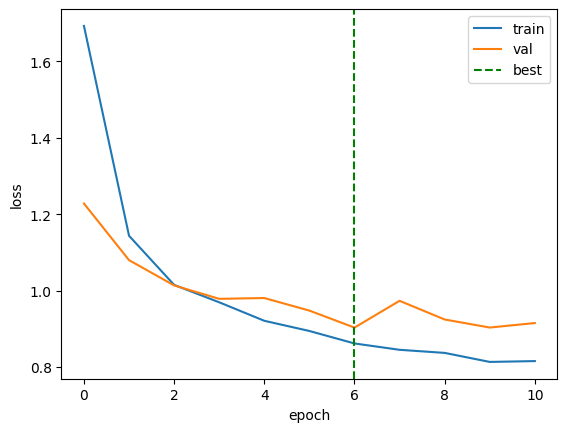

In [6]:
EPOCHS = 30
PATIENCE = 4          # stop if val hasn't improved for this many epochs
MAX_FRAMES = 1500

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for X, S, On, Off, Hard, mask, lens, sexes in loader:
            ms = MAX_FRAMES * HOP
            X, S = X[:, :, :ms].to(device), S[:, :MAX_FRAMES].to(device)
            On, Off = On[:, :MAX_FRAMES].to(device), Off[:, :MAX_FRAMES].to(device)
            mask = mask[:, :MAX_FRAMES].to(device)
            st, on, off = model(X)
            loss, _ = combined_loss(st, on, off, S, On, Off, mask)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            tot += loss.item()*X.size(0); n += X.size(0)
            del X, S, On, Off, st, on, off, loss
    torch.cuda.empty_cache()
    return tot/n

hist = {"train": [], "val": []}
best_val = float("inf"); best_epoch = 0; wait = 0

for epoch in range(1, EPOCHS+1):
    tr = run_epoch(train_loader, True)
    va = run_epoch(val_loader, False)
    hist["train"].append(tr); hist["val"].append(va)
    flag = ""
    if va < best_val:
        best_val = va; best_epoch = epoch; wait = 0
        torch.save(model.state_dict(), "best.pt")     # save the best model
        flag = "  <-- best (saved)"
    else:
        wait += 1
    print(f"epoch {epoch:2d} | train {tr:.3f} | val {va:.3f}{flag}")
    if wait >= PATIENCE:
        print(f"early stop: no val improvement for {PATIENCE} epochs")
        break

# restore the best model before evaluating
model.load_state_dict(torch.load("best.pt"))
print(f"\nLoaded best model from epoch {best_epoch} (val {best_val:.3f})")

plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.axvline(best_epoch-1, color="green", ls="--", label="best")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

In [7]:
def predict_probs(loader):
    model.eval()
    On, Off, T, S = [], [], [], []
    with torch.no_grad():
        for X, St, Onb, Offb, Hard, mask, lens, sexes in loader:
            st, on, off = model(X.to(device))
            on  = torch.sigmoid(on).cpu(); off = torch.sigmoid(off).cpu()
            for b in range(X.size(0)):
                L = lens[b].item()
                On.append(on[b, :L].numpy()); Off.append(off[b, :L].numpy())
                T.append(Hard[b, :L].numpy()); S.append(sexes[b])
    return On, Off, T, S

def pick_peaks(prob, thr, min_gap=3):
    peaks = []
    for i in range(len(prob)):
        if prob[i] < thr: continue
        lo, hi = max(0,i-1), min(len(prob), i+2)
        if prob[i] == prob[lo:hi].max() and (not peaks or i-peaks[-1] >= min_gap):
            peaks.append(i)
    return set(peaks)

def event_f1(prob_list, trues, class_id, thr, tol=2):
    tp=fp=fn=0
    for prob, t in zip(prob_list, trues):
        pred = pick_peaks(prob, thr)
        t_idx = list(np.where(t==class_id)[0]); matched=set()
        for ti in t_idx:
            hit=next((pi for pi in pred if abs(pi-ti)<=tol and pi not in matched), None)
            if hit is not None: tp+=1; matched.add(hit)
            else: fn+=1
        fp+=len(pred-matched)
    prec=tp/(tp+fp) if tp+fp else 0.0
    rec =tp/(tp+fn) if tp+fn else 0.0
    f1  =2*prec*rec/(prec+rec) if prec+rec else 0.0
    return prec,rec,f1

# 1) pick best threshold on VALIDATION
vOn, vOff, vT, vS = predict_probs(val_loader)
best_thr, best_f1 = 0.5, 0.0
for thr in [0.2,0.3,0.4,0.5,0.6,0.7,0.8]:
    _,_,f1 = event_f1(vOn, vT, label_to_id["Onset"], thr)
    if f1 > best_f1: best_f1, best_thr = f1, thr
print(f"best threshold on VALIDATION: {best_thr} (val onset F1 {best_f1:.3f})")

# 2) report on TEST using that fixed threshold
On, Off, T, S = predict_probs(test_loader)
S = np.array(S)
pr,rc,f1 = event_f1(On,  T, label_to_id["Onset"],  best_thr)
print(f"\nTEST Onset  @ {best_thr} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f}")
pr,rc,f1 = event_f1(Off, T, label_to_id["Offset"], best_thr)
print(f"TEST Offset @ {best_thr} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f}")

print("\n=== onset F1 by sex (test, fixed threshold) ===")
for sex in ["male","female"]:
    idx=[i for i in range(len(On)) if S[i]==sex]
    if not idx: continue
    pr,rc,f1 = event_f1([On[i] for i in idx],[T[i] for i in idx], label_to_id["Onset"], best_thr)
    print(f"{sex:7s} | P {pr:.3f} | R {rc:.3f} | F1 {f1:.3f} | recs {len(idx)}")

best threshold on VALIDATION: 0.8 (val onset F1 0.830)

TEST Onset  @ 0.8 | P 0.832 | R 0.820 | F1 0.826
TEST Offset @ 0.8 | P 0.803 | R 0.806 | F1 0.805

=== onset F1 by sex (test, fixed threshold) ===
male    | P 0.794 | R 0.774 | F1 0.784 | recs 143
female  | P 0.883 | R 0.881 | F1 0.882 | recs 109
